# Integrating Kepler Orbits

This lab can be roughly broken down into two parts: integrating an orbit given it's 6 orbital parameters; and computing an objects orbital parameters from measurements of its position. This tutorial will go over how to accomplish the former using the Newton-Raphson method. 


### Keplerian Elements:

There are 6 degrees of freedom for a general Keplerian orbit. These six degrees of freedom can be easily labeled as the 3 position and 3 velocity components of an object in 3D space. Put an object a certain distance away from a gravitational mass and give that object an intial velocity and you will uniquely define its orbit. The problem is that drawing an orbit given only the objects position and velocity would be incredibly difficult. The solution to this problem is to convert these degrees of freedom into intuitive geometrical quantities called the Keplerian elements.

link to figure: https://en.wikipedia.org/wiki/Orbital_elements#/media/File:Orbit1.svg

![Keplerian Elements](Figures/Orbit1.svg.png "Keplerian Elements")

Here is a brief description of what they are:

These parameters define the shape of the ellipse:

**Semi-major axis ($a$):** Half of the distance from the pericenter to the apocenter. 

**Eccentricity ($e$):** A dimensionless parameter that determines the amount by which its orbit around another body deviates from a perfect circle.

These parameters define the orientation of the orbital plane relative to the ecliptic (the orbital plane of the Earth):

**Inclination ($i$):** The angle of the orbital plane and the eccliptic

**Longitude of the ascending node ($\Omega$):** Determines where the body crosses the ascending node (i.e. where the body ascends across the ecliptic plane).

**Argument of periapsis ($\omega$):** The angle between the periapsis and the ascending node.

One more parameter is needed to determine where the body currently is:

**True Anomaly ($\nu$) (The time since periapsis, $\tau$, is an alternative):** The position of the body relative to the periapsis.

These parameters are hard to get used to at the beginning, but once you are familiar, you can fairly easily estimate what an orbit looks like from these parameters.


### Mean and Eccentric Anomaly

Perhaps the fundamental problem of orbital mechanics is determining the future and past positions of an orbiting body. Simply put, the position of the object as a function of time. This is where the mean and eccentric anomaly come in. 

The mean anomaly is essentially just a restatement of Kepler's second and third laws of planetary motion. It is an angle that constantly increases with time at the mean angular velocity of the body. You can envision it geometrically as the position of an imaginary object moving around a perfectly circular orbit with the same semi-major axis and period as the body. The mean anomaly always equals the true anomaly of the body and both pericenter and apocenter. The reason this quantity is useful is because it is easily computable and linear.

$$M = \sqrt{\frac{k^2}{a^3}}(t-\tau) \qquad(1)$$

where $a$ is the semi-major axis, $\tau$ is the time of periapsis and $k$ is the Gaussian gravitational constant (essentially it just deals with our units).


Now we just need a way to compute the position of our body based on the mean anomaly. This is where the eccentric anomaly comes in. The eccentric anamoly is directly connected to the true anomaly (the position of the asteroid) as well as the mean anomaly. Geometrically, it is the projected position of the body onto the circular track that the mean anomaly is moving on. It is essentially a man in the middle that allows us to convert the mean anamoly (a well-behaved, linear quantity) to the true anomaly (the actual position of our asteroid). See the animation below:

The only problem is that there is no analytical solution that relates the eccentric anomaly, $E$, in terms of only the mean anomaly, $M$. More simply, this equation has no analytic inverse (you can try on  [Wolfram Alpha](https://www.wolframalpha.com/input/?i=inverse+f%28x%29+%3D+x+-+sin+x&assumption=%7B%22C%22%2C+%22inverse%22%7D+-%3E+%7B%22SolveWord%22%7D) if you want):

$$M = E - e sin(E)  \qquad(2)$$

where $e$ is the eccentricity. Luckily, we live in the age of computers. Using a first derivative approximation, we can write the following numeric integrator for E (M):

$$E_{n+1} = E_n + \frac{M_{i} - (E_n - esin(E_n))}{1 - ecos(E_n)}  \qquad(3)$$

Where 
$$M = \sqrt{\frac{k^2}{a^3}}(t-\tau)  \qquad(4)$$
or equivlently, 
$$M_{i+1} = M_i +   \sqrt{\frac{k^2}{a^3}}\delta t  \qquad(5)$$

Link to GIF: https://makeagif.com/gif/true-anomaly-vs-mean-anomaly-jLiSy2

![Mean Eccentric Anomalies](Figures/jLiSy2.gif "Mean Eccentric Anomalies")



In [1]:
"""
Imports
"""
import sys
sys.path.insert(0,"Lib")
import numpy as np
import matplotlib.pyplot as plt
import ta_funcs as ta

We are going to go through an example of how to integrate the orbit of a body given its orbital parameters. The lab manual goes through a method for estimating the orbital parameters of a body using only 4 observations. Using the data from Table 4 of the lab manual, we can compare the estimated orbit to the known true orbit of Ceres. 

In [2]:
"""
CONSTANTS
"""
k = 0.017202098950 #AU^(3/2) days^-1

"""
Ceres Parameters (Given in Table 4 of the Lab Manual)
"""
#Estimated
a_est = 2.947 #AU
omega_est = 80.65 #deg
i_est = 10.56 #deg
e_est = 0.125
w_est = 63.20 #deg
tau_est = 2454833 #Julian Day

#True
a = 2.766 #AU
omega = 80.72 #deg
i = 10.61 #deg
e = 0.079
w = 73.12 #deg
tau = 2454868 #Julian Day

We start by using equations (3) & (5) to integrate the orbits in time. The code is left as an exercise for the student ;)

In [3]:
#True Orbit
E, M, t = ta.newton_iterator(k, e, a, tau, dt = 0.01)
#Estimated Orbit
E_est, M_est, t_est = ta.newton_iterator(k, e_est, a_est, tau_est, dt = 0.01)

Next, we use the equations in the lab manual to convert to our desired quantity (position in polar coordinates).

In [4]:
T = t - 2450000 
r = a*(1-e*np.cos(E)) #eq 22
nu = 2*np.arctan(np.sqrt((1+e)/(1-e))*np.tan(E/2)) #eq 31
theta = nu + np.deg2rad(w) #Look above eq 36


T_est = t_est - 2450000 
r_est = a_est*(1-e_est*np.cos(E_est)) #eq 22
nu_est = 2*np.arctan(np.sqrt((1+e_est)/(1-e_est))*np.tan(E_est/2)) #eq 31
theta_est = nu_est + np.deg2rad(w_est) #Look above eq 36

Here we reproduce the Figure 3 in the lab manual showing the difference between the mean and eccentric anomaly for our integration. 

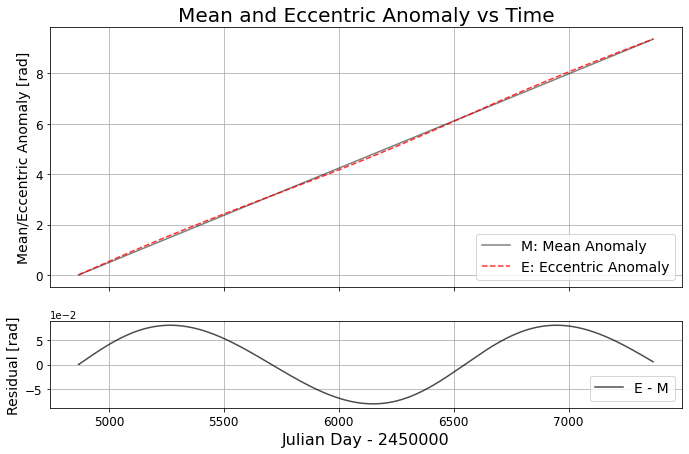

In [5]:
gr = 1.618033988749
scale = 7

f, (a0, a1) = plt.subplots(nrows=2, 
             sharex=True,
             #subplot_kw=dict(frameon=False), 
             figsize = (scale*gr, scale),
             gridspec_kw={'height_ratios': [3, 1]})
#Plot 1

a0.plot(T, M, "-", color = 'k', alpha = 0.5, label = 'M: Mean Anomaly')
a0.plot(T, E, "--", color = 'r', alpha = 0.8, label = 'E: Eccentric Anomaly')
a0.set_ylabel("Mean/Eccentric Anomaly [rad]", size = 14)
a0.set_title("Mean and Eccentric Anomaly vs Time",size = 20)
a0.legend(loc = 4, prop={'size': 14})
a0.tick_params(axis='y', labelsize=12)
a0.grid()

#Plot 2
a1.plot(T, E-M, "-", color = 'k', alpha = 0.7, label = 'E - M')
a1.set_xlabel("Julian Day - 2450000", size = 16)
a1.set_ylabel("Residual [rad]", size = 14)
a1.grid()
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
a1.tick_params(axis='x', labelsize=12)
a1.tick_params(axis='y', labelsize=12)
a1.legend(loc = 4,prop={'size': 14})

plt.show()

Here we reproduce Figure 4 from the lab manual, showing the orbital motion in polar coordinates.

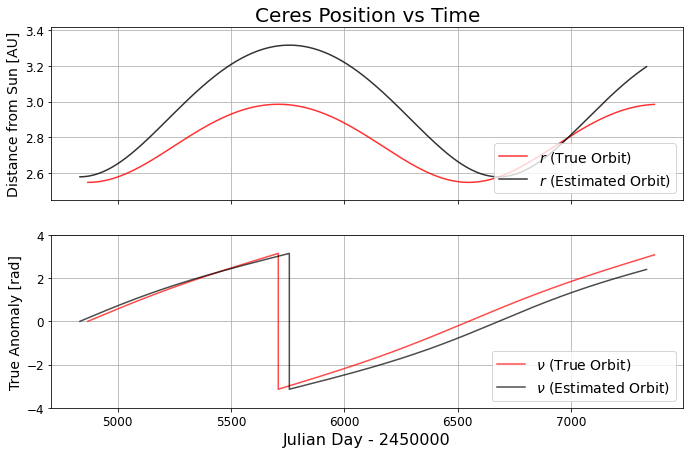

In [6]:
f, (a0, a1) = plt.subplots(nrows=2, 
             sharex=True,
             #subplot_kw=dict(frameon=False), 
             figsize = (scale*gr, scale),
             gridspec_kw={'height_ratios': [1, 1]})
#Plot 1
a0.plot(T, r, color = 'r', alpha = 0.8, label = r"$r$ (True Orbit)")
a0.plot(T_est, r_est, color = 'k', alpha = 0.8, label = r"$r$ (Estimated Orbit)")
a0.set_ylabel("Distance from Sun [AU]", size = 14)
a0.set_title("Ceres Position vs Time",size = 20)
a0.legend(loc = 4, prop={'size': 14})
a0.tick_params(axis='y', labelsize=12)
a0.grid()
a0.set_ylim(np.min(r) - 0.1,np.max(r_est) + 0.1)

#Plot 2
a1.plot(T, nu, "-", color = 'r', alpha = 0.7, label = r'$\nu$ (True Orbit)')
a1.plot(T_est, nu_est, "-", color = 'k', alpha = 0.7, label = r'$\nu$ (Estimated Orbit)')
a1.set_xlabel("Julian Day - 2450000", size = 16)
a1.set_ylabel("True Anomaly [rad]", size = 14)
a1.grid()
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
a1.tick_params(axis='x', labelsize=12)
a1.tick_params(axis='y', labelsize=12)
a1.legend(loc = 4,prop={'size': 14})
a1.set_ylim(-4,4)

plt.show()

Lastly, we reproduce Figure 5, showing the estimated orbit of Ceres compared to the known orbit and a circular reference.

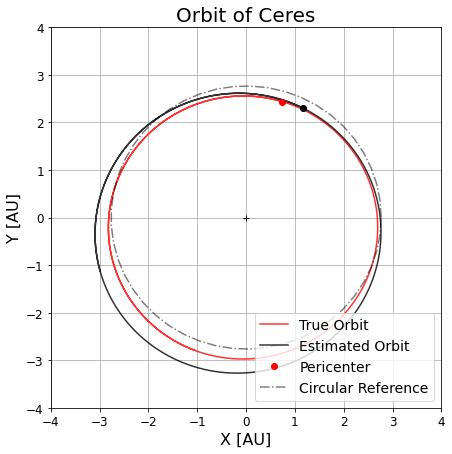

In [7]:
plt.figure(figsize=(scale,scale))

plt.plot(0, 0,'+', color = 'k')

plt.plot(r*np.cos(theta), r*np.sin(theta), color = 'r', alpha = 0.8, label = "True Orbit")

plt.plot(r_est*np.cos(theta_est), r_est*np.sin(theta_est), alpha = 0.8, color = 'k', label = "Estimated Orbit")

plt.plot(r[0]*np.cos(theta[0]), r[0]*np.sin(theta[0]), 'o', color = 'r', label = "Pericenter")
plt.plot(r_est[0]*np.cos(theta_est[0]), r_est[0]*np.sin(theta_est[0]), 'o', color = 'k')

phi = np.linspace(0, 2*np.pi)
plt.plot(a*np.cos(phi), a*np.sin(phi), '-.', color = 'k', alpha = 0.5, label = "Circular Reference")

plt.xlim(-4,4)
plt.ylim(-4,4)
plt.xlabel("X [AU]", size = 16)
plt.ylabel("Y [AU]", size = 16)
plt.grid()
plt.title("Orbit of Ceres", size = 20)
plt.legend(loc = 4,prop={'size': 14})
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.show()